### BCSE432E Reinforcement Learning Lab: L29+L30
### Lab Assignment 12

### PPO on Delivery Agent Environment

### Name: Yashvanth Karunakaran (23BAI1589)

Notebook Link: [https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-12.ipynb](https://github.com/Yashvanthk05/RL/blob/main/23BAI1589_LAB-12.ipynb)

### AIM:
To Implement a python program to apply PPO on real world delivery agent environment.

#### Install dependencies

In [1]:
%pip install -q gymnasium stable-baseline3 matplotlib numpy

/home/yashix/.zshenv:.:1: no such file or directory: /home/yashix/.cargo/env
/media/yashix/New Volume/RL/LAB/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


#### Delivery Environment
Actions: 0 - increase speed, 1 - maintain, 2 - brake

States: position, speed, traffic, road

prioritize reaching terminal state with penalty for fuel consumption and speed in traffic and poor road condition

In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

SEED = 42

class DeliveryEnv(gym.Env):
    
    def __init__(self):
        super().__init__()

        self.action_space = spaces.Discrete(3, seed = SEED) 
        self.observation_space = spaces.Box(low = 0, high = 1, shape = (4,), dtype = np.float32)

        self.speed_limit = 30
        self.max_steps = 200

    def get_state(self):
        return np.array([self.position, self.speed / self.speed_limit, self.traffic, self.road], dtype = np.float32)

    def reset(self, seed = SEED):
        super().reset(seed = SEED)

        self.steps = 0
        self.speed = 10
        self.position = 0
        self.traffic = self.np_random.uniform(0, 1)
        self.road = self.np_random.uniform(0, 1)

        return self.get_state(), {}

    def step(self, action):
        self.steps += 1

        acceleration = 0
        if action == 0:
            acceleration = 2
        elif action == 2:
            acceleration = -2

        self.speed += acceleration

        fuel = 0.02 + 0.008 * self.speed + 0.0004 * self.speed ** 2 + 0.003 * max(0, acceleration) + 0.001 * abs(acceleration)

        safe_speed = self.speed_limit * (1 - 0.55 * self.traffic - 0.25 * self.road)
        unsafe = max(0, self.speed - safe_speed)

        progress = self.speed / self.speed_limit

        reward = 2 * progress - 0.2 * fuel - 0.02 * unsafe

        self.position += self.speed / (self.speed_limit * self.max_steps)

        self.traffic = np.clip(self.traffic + self.np_random.uniform(-0.05, 0.05), 0, 1)
        self.road = np.clip(self.road + self.np_random.uniform(-0.05, 0.05), 0, 1)

        terminated = self.position >= 1
        if terminated: reward += 100

        truncated = self.steps >= self.max_steps and not terminated

        return self.get_state(), reward, terminated, truncated, {}

#### Checking whether if i had done any error in creating environment

In [3]:
from stable_baselines3.common.env_checker import check_env

env = DeliveryEnv()

check_env(env)

#### Checking how states and actions are represented

In [4]:
state, info = env.reset(seed = SEED)

print("state (position, speed, traffic, road):", state)
print("actions:", env.action_space.n)
print("observation:", env.observation_space.shape)

state (position, speed, traffic, road): [0.         0.33333334 0.77395606 0.43887845]
actions: 3
observation: (4,)


#### Randomly sampling actions and checking how rewards and other things are returned

In [5]:
state, info = env.reset()

total_reward = 0

for step in range(10):
    action = env.action_space.sample()
    state, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    print(f"{step + 1}: reward = {reward}, action = {action}")

1: reward = 0.5110133333333333, action = 2
2: reward = 0.38312, action = 2
3: reward = 0.2545866666666667, action = 2
4: reward = 0.12541333333333332, action = 2
5: reward = -0.0044, action = 2
6: reward = -0.004, action = 1
7: reward = 0.12421333333333333, action = 0
8: reward = -0.0044, action = 2
9: reward = -0.004, action = 1
10: reward = -0.004, action = 1


#### Training a PPO agent on Delivery Environment

In [6]:
from stable_baselines3 import PPO

model = PPO(policy = "MlpPolicy", env = env, learning_rate = 0.0003, seed = SEED)
model.learn(total_timesteps = 50000)

/media/yashix/New Volume/RL/LAB/.venv/lib/python3.13/site-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


#### Evaluation function for random and PPO

In [7]:
def evaluate(env, model = None, random = False, episodes = 20):
    episode_returns = []
    episode_lengths = []
    successes = 0

    for episode in range(episodes):
        state, info = env.reset(seed = SEED + episode)
        total_reward = 0
        step = 0

        while True:
            step += 1

            if random:
                action = env.action_space.sample()
            else:
                action, _ = model.predict(state, deterministic = True)

            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward

            if terminated or truncated:
                successes += int(terminated)
                break

        episode_returns.append(total_reward)
        episode_lengths.append(step)

    return {"returns": episode_returns, "lengths": episode_lengths, "successes": successes}


#### Evaluation Results by Random and PPO Agent

In [8]:
random_results = evaluate(env, random = True, episodes = 50)
ppo_results = evaluate(env, model = model, episodes = 50)

print(f"Random mean return: {np.mean(random_results['returns'])}")
print(f"PPO mean return: {np.mean(ppo_results['returns'])}")
print(f"Random success rate: {100 * random_results['successes'] / 50}%")
print(f"PPO success rate: {100 * ppo_results['successes'] / 50}%")

Random mean return: 141.88171840264826
PPO mean return: 344.9884771356645
Random success rate: 14.0%
PPO success rate: 100.0%


#### Episode Returns for Random and PPO Agent

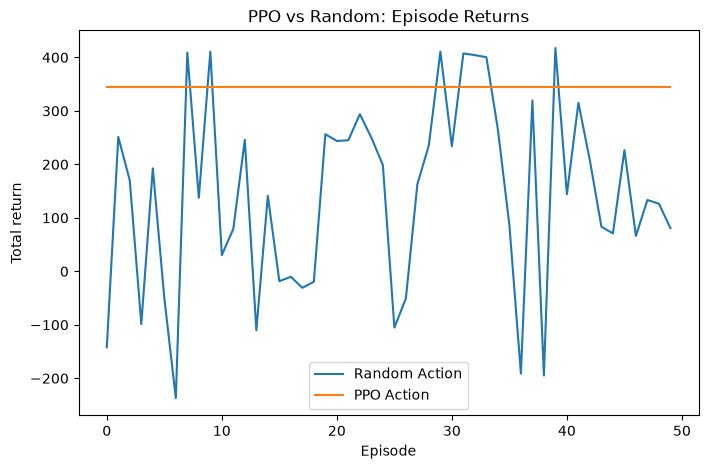

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize = (8, 5))
plt.plot(random_results["returns"], label = "Random Action")
plt.plot(ppo_results["returns"], label = "PPO Action")
plt.xlabel("Episode")
plt.ylabel("Total return")
plt.title("PPO vs Random: Episode Returns")
plt.legend()
plt.show()

#### Episode Length for PPO and Random Agent

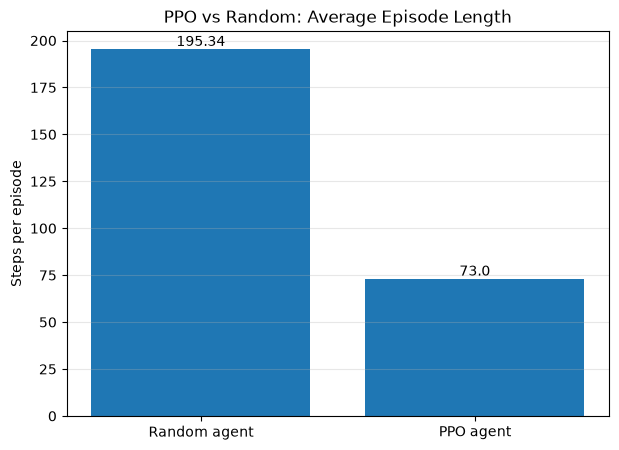

In [10]:
average_lengths = [np.mean(random_results["lengths"]), np.mean(ppo_results["lengths"])]

plt.figure(figsize = (7, 5))
plt.bar_label(plt.bar(["Random agent", "PPO agent"], average_lengths),labels = average_lengths)
plt.ylabel("Steps per episode")
plt.title("PPO vs Random: Average Episode Length")
plt.grid(axis = "y", alpha = 0.3)
plt.show()

#### Conclusion

PPO agent learns to select delivery actions based on position, speed, traffic, and road conditions. Compared with the random agent, PPO generally achieves better rewards because it learns from its experience